# Customer Segmentation with K-Means

This notebook groups mall customers into natural segments based on their **Annual Income** and **Spending Score** — with no target column and no labels telling it the "right" groups. It builds on an earlier working script, adding the documentation, defensive checks, and evaluation that script didn't yet have.

### What's different from the starting script
The original version loaded the data, dropped missing values unconditionally, scaled, ran the elbow method, and plotted the result. This version keeps that same shape and those same variable names, but adds:
- **Checks before actions** — confirming there's something to clean before cleaning it
- **Silhouette score**, not just inertia — a clustering model isn't "done" once it runs; it's done once it's been evaluated
- **Cluster profiling** — turning cluster numbers (0, 1, 2, ...) into segments a retailer could actually act on

---
# Part A — Import Data from File

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# In Colab this reads from the same machine_learning folder on Drive used elsewhere.
# Locally (or from a cloned repo) it reads the CSV sitting next to the notebook.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    file_path = "/content/drive/My Drive/machine_learning/Mall_Customers.csv"
except ImportError:
    file_path = "Mall_Customers.csv"

df = pd.read_csv(file_path)

print("✅ Dataset loaded successfully!")
print("Shape:", df.shape)
df.head(10)

✅ Dataset loaded successfully!
Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


## A.1 — First Look

Before touching anything, a quick inventory: what columns exist, what type is each, and roughly what range of values to expect.

In [2]:
print(df.dtypes)
print()
print(df.describe())

CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.000000               73.000000
max    200.000000   70.000000          137.000000               99.000000


---
# Part B — Handle Missing Values

The original script ran `df.dropna(inplace=True)` unconditionally. Here, the check comes first — dropping rows is only the right move if there's something to drop, and doing it blindly hides whether the dataset actually had a problem.

In [3]:
missing_counts = df.isnull().sum()
print(missing_counts)
print("\nTotal missing values:", missing_counts.sum())

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Total missing values: 0


In [4]:
# Only drop rows if missing values actually exist
if missing_counts.sum() > 0:
    before = df.shape[0]
    df.dropna(inplace=True)
    print(f"Dropped {before - df.shape[0]} rows with missing values.")
else:
    print("No missing values found — nothing to drop.")

No missing values found — nothing to drop.


## B.1 — Check for Duplicates Too

Missing values are only one kind of data quality issue. A quick check for duplicate rows — and duplicate customers — costs one line and catches a different kind of problem entirely.

In [5]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Customer IDs:", df["CustomerID"].duplicated().sum())

Duplicate rows: 0
Duplicate Customer IDs: 0


---
# Part C — Feature Selection

K-Means clusters customers by how similar their behaviour is — not by any text or identifier. Two features drive the clustering here, the same pair used in the classic version of this exercise:
- **Annual Income (k$)** — how much a customer earns
- **Spending Score (1-100)** — a mall-assigned score for how much a customer spends; higher means more willing to spend

`CustomerID` is kept alongside them for reference — to identify which customer ends up in which segment later — but it is never fed into the clustering itself: an ID number carries no meaningful notion of "distance" between customers. `Gender` and `Age` are left out too, so the clustering stays a clean 2D picture that can be plotted directly and compared to the well-known result for this dataset.

In [6]:
selected_features = df[["CustomerID", "Annual Income (k$)", "Spending Score (1-100)"]]
selected_features.describe()

,CustomerID,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000
mean,100.500000,60.560000,50.200000
std,57.879185,26.264721,25.823522
min,1.000000,15.000000,1.000000
25%,50.750000,41.500000,34.750000
50%,100.500000,61.500000,50.000000
75%,150.250000,78.000000,73.000000
max,200.000000,137.000000,99.000000


---
# Part D — Normalise the Data

This is the step that matters more for K-Means than it did for the classifiers and regressors earlier this course. Random Forest didn't care about scale. Linear Regression cared about encoding, not scale. **K-Means groups points by distance, so scale is everything.**

Annual Income here runs into the tens of thousands of dollars; Spending Score runs from 1 to 100. Left unscaled, Annual Income alone would decide almost every clustering outcome.

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_data = scaler.fit_transform(selected_features[["Annual Income (k$)", "Spending Score (1-100)"]])

print("Scaled feature means (should be ~0):", scaled_data.mean(axis=0).round(4))
print("Scaled feature std (should be ~1):", scaled_data.std(axis=0).round(4))

Scaled feature means (should be ~0): [-0. -0.]
Scaled feature std (should be ~1): [1. 1.]


---
# Part E — Find Optimal k

## E.1 — The Elbow Method

K-Means has to be told how many clusters (k) to look for — it doesn't suggest a number on its own. The elbow method runs K-Means for a range of k values and tracks **inertia**: the total squared distance from every point to its own cluster's centroid. More clusters always lowers inertia; the goal is to spot where adding another cluster stops buying much.

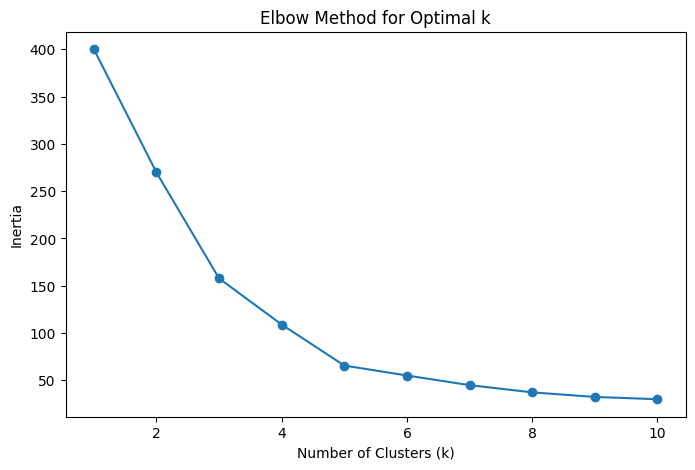

In [8]:
from sklearn.cluster import KMeans

inertia = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_data)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.show()

**Reading this result:** inertia drops sharply through k=4, then bends noticeably at **k=5** (109 → 66) before flattening out — a clear elbow at 5.

## E.2 — Silhouette Score — a Second Opinion

The elbow method is a visual heuristic; the silhouette score is a quantitative check. It measures how similar each point is to its own cluster versus the next-nearest one, ranging from −1 (likely the wrong cluster) to +1 (well-matched and well-separated). The elbow chart alone isn't the full picture — this is the evaluation step the original script didn't have.

In [9]:
from sklearn.metrics import silhouette_score

silhouette_scores = {}
for k in range(2, 11):  # silhouette score is undefined for k=1
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(scaled_data)
    silhouette_scores[k] = silhouette_score(scaled_data, labels)

for k, score in silhouette_scores.items():
    print(f"k={k}: silhouette score = {score:.4f}")

k=2: silhouette score = 0.3213
k=3: silhouette score = 0.4666
k=4: silhouette score = 0.4939
k=5: silhouette score = 0.5547
k=6: silhouette score = 0.5399
k=7: silhouette score = 0.5281
k=8: silhouette score = 0.4552
k=9: silhouette score = 0.4571
k=10: silhouette score = 0.4432


**Reading this result:** unlike a lot of real-world data, there's no tension to resolve here — the elbow and the silhouette score agree. k=5 scores highest (≈ 0.555), clearly ahead of k=4 (≈ 0.494) and k=6 (≈ 0.540), and it lines up with the elbow bend above. **k=5 is chosen because the statistics and the elbow point to the same answer** — and, as the profiling in Part H confirms, it also happens to produce the five classic, well-understood segments for this dataset (by income and spending: average, high-high, low-high, high-low, low-low).

---
# Part F — Apply K-Means with the Chosen k

In [10]:
# The elbow method and silhouette score both point to k=5 for this dataset
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(scaled_data)

print("Cluster sizes:")
print(df["Cluster"].value_counts().sort_index())

Cluster sizes:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


---
# Part G — Visualise the Clusters

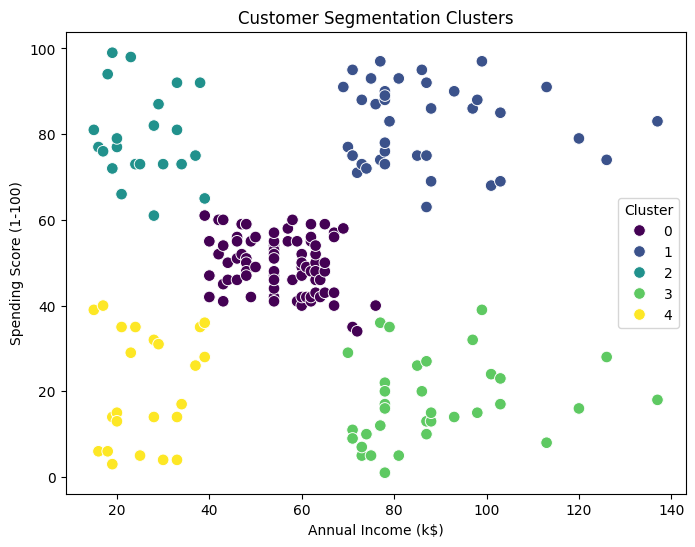

In [11]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=df["Annual Income (k$)"], y=df["Spending Score (1-100)"], hue=df["Cluster"], palette="viridis", s=70)
plt.title("Customer Segmentation Clusters")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()

---
# Part H — Model Evaluation

## H.1 — Inertia and Silhouette Score for the Final Model

The same two numbers from Part E, now reported for the model actually being used — the headline evaluation figures for this clustering.

In [12]:
final_inertia = kmeans.inertia_
final_silhouette = silhouette_score(scaled_data, df["Cluster"])

print(f"Inertia (k=5): {final_inertia:.2f}")
print(f"Silhouette Score (k=5): {final_silhouette:.4f}")

Inertia (k=5): 65.57
Silhouette Score (k=5): 0.5547


**Reading this result:** a silhouette score of 0.555 is a strong result for real customer data — well-separated, well-matched clusters, and it's also the best this dataset can offer across every k tested (Part E.2). Inertia on its own means little in isolation; it only becomes meaningful compared across different k values, as in the elbow chart above.

## H.2 — Profiling Each Cluster

A cluster is just a number (0, 1, 2) until its actual characteristics are examined. This is the step that turns a clustering output into something a business can use.

In [13]:
cluster_profile = df.groupby("Cluster")[["Annual Income (k$)", "Spending Score (1-100)"]].agg(["mean", "count"]).round(2)
cluster_profile

Annual Income (k$)       Spending Score (1-100)      
                      mean count                   mean count
Cluster                                                      
0                    55.30    81                  49.52    81
1                    86.54    39                  82.13    39
2                    25.73    22                  79.36    22
3                    88.20    35                  17.11    35
4                    26.30    23                  20.91    23

## H.3 — Naming the Segments

K-Means never sees these names — it only sees numbers. Labels are assigned after looking at what each cluster actually contains, informed by the profile above.

In [14]:
segment_names = {
    0: "Average Income, Average Spending",
    1: "High Income, High Spending (Target)",
    2: "Low Income, High Spending (Careless)",
    3: "High Income, Low Spending (Careful)",
    4: "Low Income, Low Spending (Sensible)",
}

# Confirm which cluster number corresponds to which profile before trusting this mapping —
# cluster numbers are arbitrary and can shuffle between runs with a different random_state.
cluster_check = df.groupby("Cluster")[["Annual Income (k$)", "Spending Score (1-100)"]].mean().round(1)
print("Cluster profiles (confirm these match the segment_names mapping above):")
print(cluster_check)

Cluster profiles (confirm these match the segment_names mapping above):
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                      55.3                    49.5
1                      86.5                    82.1
2                      25.7                    79.4
3                      88.2                    17.1
4                      26.3                    20.9


**Important:** before applying the `segment_names` mapping above, confirm the cluster numbers printed here actually show the five expected profiles (roughly: mid/mid, high/high, low/high, high/low, low/low) — cluster labels (0–4) are assigned arbitrarily by the algorithm and are not guaranteed to land on the same numbers every run. Adjust the dictionary to match what you see before proceeding.

In [15]:
df["Segment"] = df["Cluster"].map(segment_names)
df[["CustomerID", "Annual Income (k$)", "Spending Score (1-100)", "Cluster", "Segment"]].head(10)

,CustomerID,Annual Income (k$),Spending Score (1-100),Cluster,Segment
0,1,15,39,4,"Low Income, Low Spending (Sensible)"
1,2,15,81,2,"Low Income, High Spending (Careless)"
2,3,16,6,4,"Low Income, Low Spending (Sensible)"
3,4,16,77,2,"Low Income, High Spending (Careless)"
4,5,17,40,4,"Low Income, Low Spending (Sensible)"
5,6,17,76,2,"Low Income, High Spending (Careless)"
6,7,18,6,4,"Low Income, Low Spending (Sensible)"
7,8,18,94,2,"Low Income, High Spending (Careless)"
8,9,19,3,4,"Low Income, Low Spending (Sensible)"
9,10,19,72,2,"Low Income, High Spending (Careless)"


---
# Summary

| Step | What Happened |
|---|---|
| Missing values / duplicates | Checked explicitly; none found in this sample |
| Features | Annual Income (k$) and Spending Score (1-100) — CustomerID kept for reference only, Gender/Age left out of the clustering |
| Scaling | Required here specifically, because K-Means is distance-based and these two features sit on very different scales |
| Choosing k | Elbow method and silhouette score both considered; k=5 chosen because the two agree — no elbow-vs-business-judgement trade-off was needed this time |
| Evaluation | Inertia and silhouette score (0.555) reported for the final model — a clustering model is not finished once it runs, only once it's checked |
| Segments found | Average, Target (high income/high spending), Careless (low income/high spending), Careful (high income/low spending), and Sensible (low income/low spending) — named only after inspecting what each cluster actually contained |

The most important idea in this notebook isn't a specific metric — it's that **unsupervised results need interpretation before they're useful.** A cluster number means nothing on its own; the profiling and naming in Part H is what turns five arbitrary groups into something a retail team could act on.